# 03 · Train a graph model to order—not certify—candidate patches

The supervised target is whether a legal candidate batch produces the requested next action. Labels come from the exact simulator. Every candidate from one underlying scene stays in the same split.

This notebook performs a **three-epoch learning exercise**. The release contains separate fourteen-epoch runs for three model types and three seeds. Do not substitute the exercise checkpoint for the reported release checkpoints without rerunning evaluation.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "belieftown").exists():
    raise RuntimeError("Run this notebook from the source repository or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
RUN_ROOT = Path(os.environ["BELIEFTOWN_RUN_ROOT"]).resolve() if os.environ.get("BELIEFTOWN_RUN_ROOT") else None
DATA = RUN_ROOT / "data" if RUN_ROOT else ROOT / "benchmarks" / "data"
CHECKPOINTS = RUN_ROOT / "checkpoints" if RUN_ROOT else ROOT / "artifacts" / "checkpoints"
REPORT = RUN_ROOT / "evaluation" if RUN_ROOT else ROOT / "artifacts" / "evaluation"
AUDIT_DIR = RUN_ROOT if RUN_ROOT else ROOT / "artifacts"
OUTPUT = AUDIT_DIR / "notebook_run"
OUTPUT.mkdir(parents=True, exist_ok=True)
import numpy as np
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, HTML

In [2]:
from belieftown.learning.data import load_cases
from belieftown.learning.graph import encode_graph
from belieftown.learning.model import GraphRanker, Predictor, configure
from belieftown.interventions import candidate_deliveries, search
manifest = json.loads((DATA / "manifest.json").read_text())
train_cases = load_cases(DATA / "train.jsonl")
validation_cases = load_cases(DATA / "validation.jsonl")
assert not ({c.scene.hash for c in train_cases} & {c.scene.hash for c in validation_cases})
print("Training scenes:", len(train_cases))
print("Validation scenes:", len(validation_cases))
print("Training candidate labels:", manifest["splits"]["train"]["candidates"])
print("Positive candidate fraction:", manifest["splits"]["train"]["positive_candidates"] / manifest["splits"]["train"]["candidates"])

Training scenes: 120
Validation scenes: 24
Training candidate labels: 7104
Positive candidate fraction: 0.0843186936936937


## Relational message passing

Nodes represent rooms, actors, original observations, messages, and proposed deliveries. Edges retain their semantic types. No hidden parcel truth or arbitrary numeric identifier is a feature.

$$h_v^{(\ell+1)}=\operatorname{ReLU}\left(W_{self}^{(\ell)}h_v^{(\ell)}+
\sum_r\frac{1}{\max(1,|N_r(v)|)}\sum_{u\in N_r(v)}W_r^{(\ell)}h_u^{(\ell)}\right).$$

The implementation uses two layers, 32 hidden coordinates, 20 input features, 21 relation types, and 14 graph-level numerical features. A mean-pooled graph embedding is concatenated with target and destination embeddings. The non-graph comparator receives pooled node features and the same global features, including a strong likelihood heuristic.

Node-feature matrix: (14, 20)
Typed edges: (46, 3)
Trainable parameters: 52961


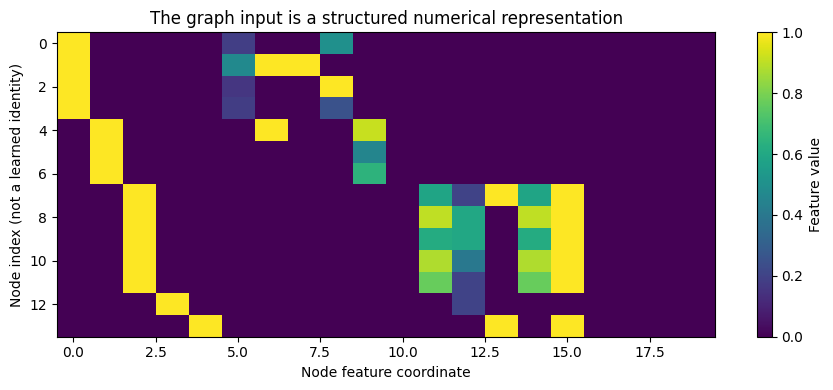

In [3]:
configure(0)
case = train_cases[0]
snap = case.snapshot
candidates = candidate_deliveries(snap, case.problem)
graph = encode_graph(snap, case.problem, candidates[:1])
model = GraphRanker()
print("Node-feature matrix:", graph.x.shape)
print("Typed edges:", graph.edges.shape)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
plt.figure(figsize=(9, 4))
plt.imshow(graph.x, aspect="auto")
plt.xlabel("Node feature coordinate")
plt.ylabel("Node index (not a learned identity)")
plt.title("The graph input is a structured numerical representation")
plt.colorbar(label="Feature value")
plt.tight_layout()
plt.show()

## Train against execution labels

With logits $s_\theta$ and $\hat p=\operatorname{sigmoid}(s_\theta)$, minimize binary cross-entropy:

$$\mathcal L=-\frac1M\sum_n\left[y_n\log\hat p_n+(1-y_n)\log(1-\hat p_n)\right].$$

The positive class is sparse. Accuracy alone would be misleading. Validation binary cross-entropy selects a checkpoint; neither the test split nor OOD cases select training epochs.

Selected epoch: 2
Validation BCE: 0.09207679631063612
Training seconds: 14.678127370999846


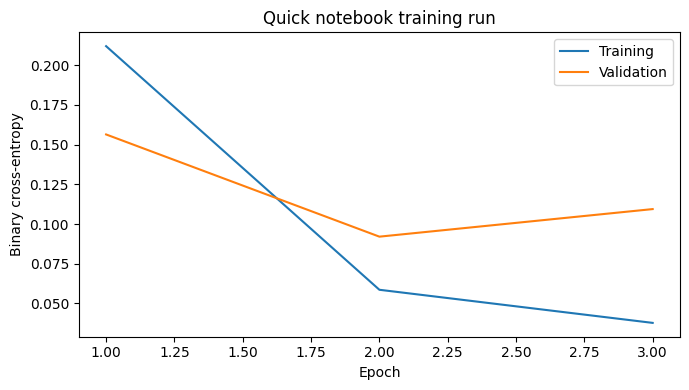

In [4]:
from belieftown.learning.train import train_model
EPOCHS = 3
predictor = train_model(DATA, OUTPUT / "graph_quick.pt", kind="graph", seed=11, epochs=EPOCHS)
print("Selected epoch:", predictor.metadata["best_epoch"])
print("Validation BCE:", predictor.metadata["validation_bce"])
print("Training seconds:", predictor.metadata["training_seconds"])
history = predictor.metadata["history"]
plt.figure(figsize=(7, 4))
plt.plot([h["epoch"] for h in history], [h["train_bce"] for h in history], label="Training")
plt.plot([h["epoch"] for h in history], [h["validation_bce"] for h in history], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Quick notebook training run")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Saving/loading preserves predictions; the exact verifier remains the authority.
loaded = Predictor.load(OUTPUT / "graph_quick.pt")
a = predictor.score(snap, case.problem, [()])
b = loaded.score(snap, case.problem, [()])
np.testing.assert_array_equal(a, b)
from belieftown.scenarios import demo_scene
from belieftown.world import Episode
from belieftown.interventions import PatchProblem
scene = demo_scene()
result = search(Episode(scene).at(4), PatchProblem("courier", 1), method="graph", ranker=loaded)
assert result.status == "verified_minimum_within_bounds"
print("Learned ordering, exact result:", result.status, result.patch)

Learned ordering, exact result: verified_minimum_within_bounds (Delivery(sender='mira', recipient='courier', root_id='new-library'),)


**Do not conclude that the model is faster because it returns a valid patch.** Its encoding and inference cost must be included. Notebook 04 examines the released paired benchmark, including the result that the heuristic is faster on these small scenes.